In [1]:
import starfile
from findingampa.utils.analysis import render_active_zonograms, calculate_probit, estimate_anisotropic_gaussian_for_probit, calculate_1q_p_value, render_active_zonograms, select_aunps
import pymeshlab
from pathlib import Path
from scipy.spatial import cKDTree
from matplotlib import pyplot as plt
import torch
import mrcfile
import numpy as np
import json
from scipy.spatial import cKDTree
import rustworkx as rx
import torch
import roma
import einops

%matplotlib inline
def load_tomogram(az):
    with mrcfile.open(az, permissive=True) as mrc:
        res_ddw = torch.tensor(mrc.data.copy())
    
    return res_ddw, res_ddw.shape

In [2]:
basefolder = Path("/scratch/pompeii/elferich/gouaux_tomo/graph/graph/")

tomos = [("20231026_HippAu_14","0")]

In [3]:
aunps_data = starfile.read(basefolder / tomos[0][0] / "fiducial_tracking" /"aunps"/"aunp_tm_BP_active_zone_0.star")
print(basefolder / tomos[0][0] / "fiducial_tracking" /"aunps"/"aunp_tm_BP_active_zone_0.star")
coordinates = aunps_data[["faCoordinateX", "faCoordinateY", "faCoordinateZ"]].values 


/scratch/pompeii/elferich/gouaux_tomo/graph/graph/20231026_HippAu_14/fiducial_tracking/aunps/aunp_tm_BP_active_zone_0.star


In [4]:

kdt = cKDTree(coordinates)
pairs = kdt.query_pairs(10,output_type="ndarray")
distances = np.linalg.norm(coordinates[pairs[:,0]] - coordinates[pairs[:,1]], axis=1)
#pairs = pairs[distances > 5]

In [5]:
len(pairs)

147

In [6]:
graph = rx.PyGraph()

In [7]:
graph.add_nodes_from(range(len(coordinates)))

NodeIndices[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151]

In [8]:
for i, j in pairs:
    graph.add_edge(i,j,None)


In [9]:
graph.edge_list()

EdgeList[(1, 94), (76, 108), (22, 108), (12, 76), (22, 76), (50, 78), (26, 78), (50, 98), (78, 98), (7, 141), (10, 141), (90, 141), (101, 141), (90, 101), (101, 140), (117, 140), (90, 115), (90, 150), (37, 83), (40, 83), (48, 100), (111, 115), (113, 115), (40, 48), (48, 111), (48, 113), (111, 113), (100, 138), (51, 100), (45, 113), (113, 150), (45, 150), (45, 51), (34, 45), (34, 150), (51, 138), (51, 86), (59, 103), (91, 103), (34, 86), (17, 83), (120, 138), (59, 120), (59, 93), (91, 131), (103, 131), (17, 41), (41, 110), (119, 127), (3, 147), (3, 112), (112, 147), (93, 120), (116, 147), (104, 121), (104, 116), (31, 112), (112, 116), (142, 146), (126, 146), (135, 146), (146, 151), (131, 142), (84, 135), (126, 151), (80, 126), (135, 151), (80, 135), (80, 151), (31, 118), (31, 116), (56, 66), (35, 118), (35, 116), (35, 149), (66, 149), (63, 72), (63, 102), (16, 129), (57, 129), (16, 28), (67, 145), (63, 96), (70, 82), (82, 145), (70, 145), (30, 82), (82, 143), (30, 145), (2, 19), (42, 77

In [10]:
subgraphs_4 = rx.connected_subgraphs(graph,4)
len(subgraphs_4)

322

In [11]:
graph.edge_list()

EdgeList[(1, 94), (76, 108), (22, 108), (12, 76), (22, 76), (50, 78), (26, 78), (50, 98), (78, 98), (7, 141), (10, 141), (90, 141), (101, 141), (90, 101), (101, 140), (117, 140), (90, 115), (90, 150), (37, 83), (40, 83), (48, 100), (111, 115), (113, 115), (40, 48), (48, 111), (48, 113), (111, 113), (100, 138), (51, 100), (45, 113), (113, 150), (45, 150), (45, 51), (34, 45), (34, 150), (51, 138), (51, 86), (59, 103), (91, 103), (34, 86), (17, 83), (120, 138), (59, 120), (59, 93), (91, 131), (103, 131), (17, 41), (41, 110), (119, 127), (3, 147), (3, 112), (112, 147), (93, 120), (116, 147), (104, 121), (104, 116), (31, 112), (112, 116), (142, 146), (126, 146), (135, 146), (146, 151), (131, 142), (84, 135), (126, 151), (80, 126), (135, 151), (80, 135), (80, 151), (31, 118), (31, 116), (56, 66), (35, 118), (35, 116), (35, 149), (66, 149), (63, 72), (63, 102), (16, 129), (57, 129), (16, 28), (67, 145), (63, 96), (70, 82), (82, 145), (70, 145), (30, 82), (82, 143), (30, 145), (2, 19), (42, 77

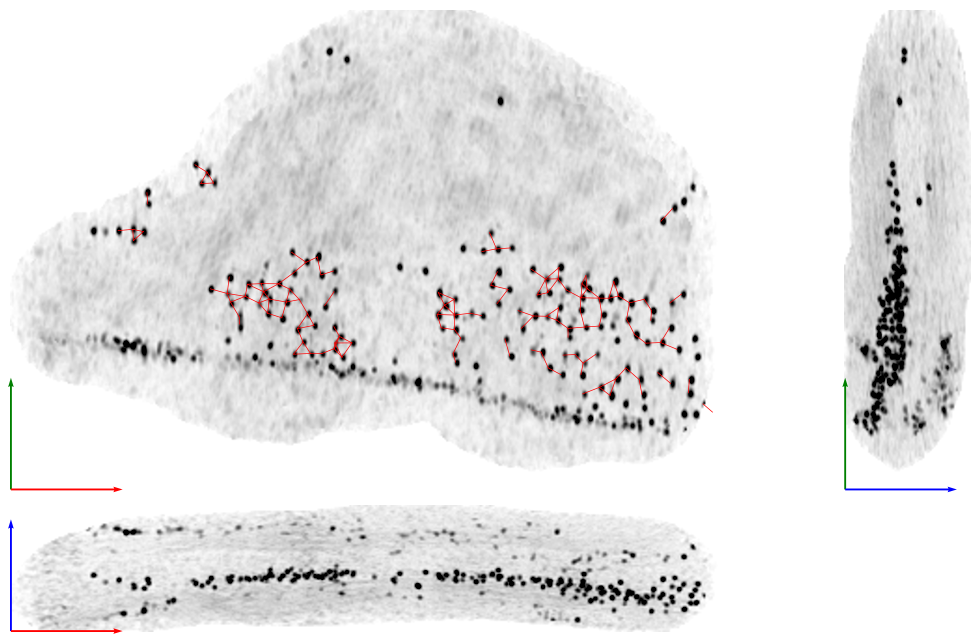

In [12]:
az = basefolder / tomos[0][0] / "fiducial_tracking" / "active_zonograms" / f"active_zonogram_{tomos[0][1]}.mrc"
res_ddw, rshape = load_tomogram(az)
fig = render_active_zonograms((None,None,res_ddw))
az_data = np.load(az.with_suffix(".npy") ,allow_pickle=True)
selected_aunp_pos_transformed = (coordinates - az_data.tolist()["center"]) @ az_data.tolist()["cs"].T
selected_aunp_pos_transformed += np.floor(np.array(rshape)[[2,1,0]]/2)
selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed > 0, axis=1)]
selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed < np.array(rshape)[[2,1,0]], axis=1)]

(axxy, axxz, axyz) = fig.get_axes()

#axxy.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,1], c="b", s=5)
for e in graph.edge_list():
    axxy.plot(
        [selected_aunp_pos_transformed[e[0],0], selected_aunp_pos_transformed[e[1],0]],
        [selected_aunp_pos_transformed[e[0],1], selected_aunp_pos_transformed[e[1],1]],
        c="r", lw=0.5
    )
fig

In [13]:

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
colors

['#1f77b4',
 '#ff7f0e',
 '#2ca02c',
 '#d62728',
 '#9467bd',
 '#8c564b',
 '#e377c2',
 '#7f7f7f',
 '#bcbd22',
 '#17becf']

In [46]:
[i for i,s in enumerate(subgraphs_4) if 12 in s]

[34]

In [45]:
selected_aunp_pos_transformed = (coordinates - az_data.tolist()["center"]) @ az_data.tolist()["cs"].T
selected_aunp_pos_transformed += np.floor(np.array(rshape)[[2,1,0]]/2)
np.nonzero(selected_aunp_pos_transformed[:,0] < 100)

(array([ 1, 12, 26, 46, 50, 78, 94, 98]),)

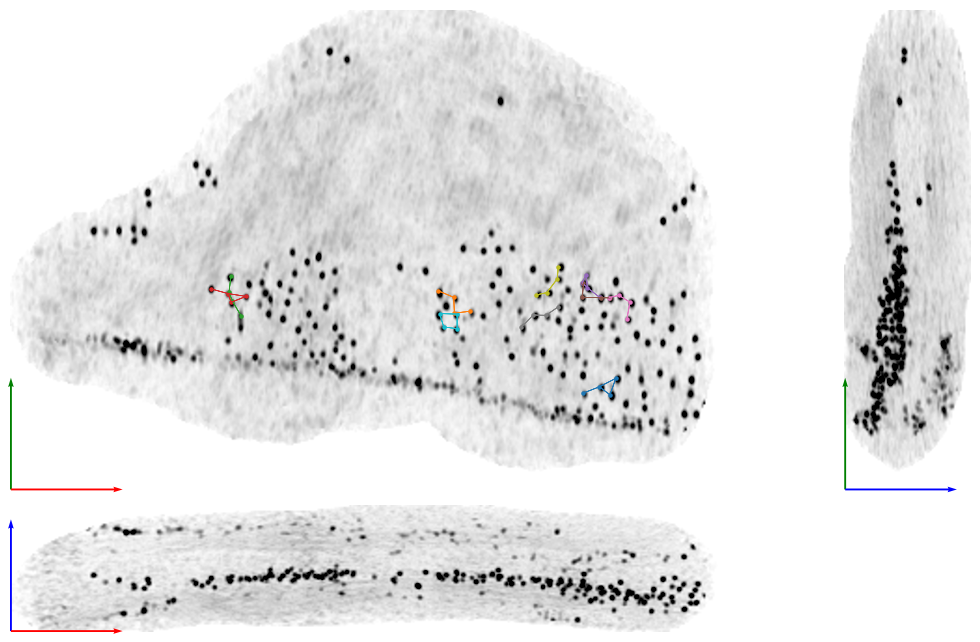

In [14]:
from itertools import permutations
from numpy.random import normal
plt.close()
fig = render_active_zonograms((None,None,res_ddw))

for i in range(len(colors)):
    subgraph = subgraphs_4[i*10]
    selected_aunp_pos_transformed = (coordinates[subgraph] - az_data.tolist()["center"]) @ az_data.tolist()["cs"].T
    selected_aunp_pos_transformed += np.floor(np.array(rshape)[[2,1,0]]/2)
    #selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed > 0, axis=1)]
    #selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed < np.array(rshape)[[2,1,0]], axis=1)]

    (axxy, axxz, axyz) = fig.get_axes()
    jitter = normal(0, 0.5, size=2)  # Adjust the standard deviation as needed
    axxy.scatter(selected_aunp_pos_transformed[:,0]+ jitter[0], selected_aunp_pos_transformed[:,1] + jitter[1], c=colors[i], s=5)
    
    for perm in permutations(range(len(subgraph))):
        if graph.has_edge(subgraph[perm[0]], subgraph[perm[1]]):
            

            axxy.plot(
                [
                    selected_aunp_pos_transformed[perm[0], 0] + jitter[0],
                    selected_aunp_pos_transformed[perm[1], 0] + jitter[0],
                ],
                [
                    selected_aunp_pos_transformed[perm[0], 1] + jitter[1],
                    selected_aunp_pos_transformed[perm[1], 1] + jitter[1],
                ],
                c=colors[i],
                lw=0.5,
            )
fig

[78, 26, 50, 98]
[[ 65.44297862 139.69528128  25.24317567]
 [ 57.54254254 139.01804406  27.89269734]
 [ 71.15359756 138.48053622  23.27457132]
 [ 65.78257629 133.60425023  23.74692923]]
[22, 108, 12, 76]
[[101.92970195 164.29238517  24.66947883]
 [108.8780249  164.58926249  23.84323328]
 [ 98.78991397 174.39907479  26.09424186]
 [105.3185393  170.41293629  26.66903861]]


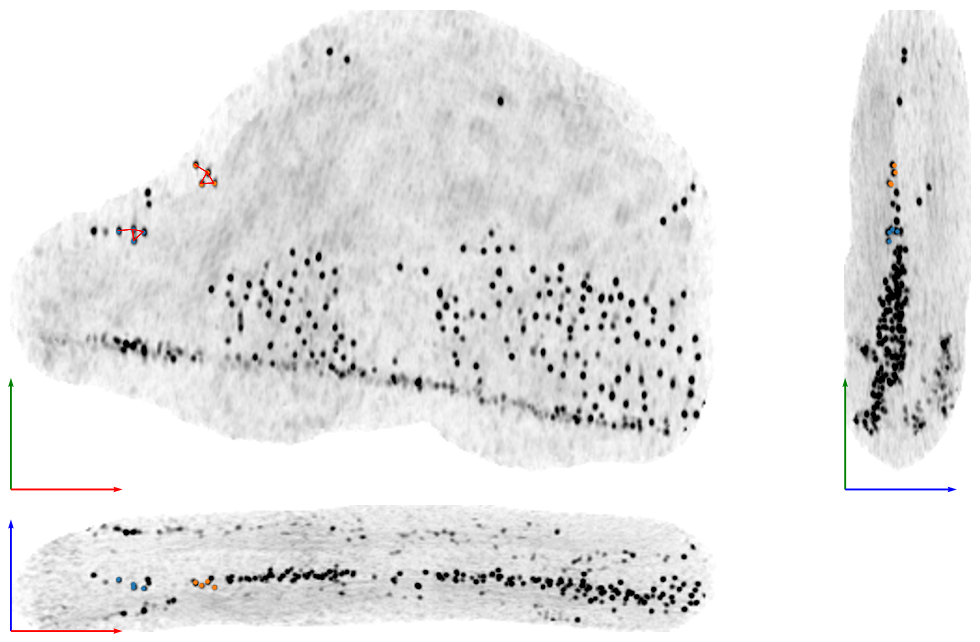

In [51]:
from itertools import permutations
from numpy.random import normal
plt.close()
fig = render_active_zonograms((None,None,res_ddw))

for i in [66,34]:
    subgraph = subgraphs_4[i]
    selected_aunp_pos_transformed = (coordinates[subgraph] - az_data.tolist()["center"]) @ az_data.tolist()["cs"].T
    selected_aunp_pos_transformed += np.floor(np.array(rshape)[[2,1,0]]/2)
    print(subgraph)
    print(selected_aunp_pos_transformed)
    #selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed > 0, axis=1)]
    #selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed < np.array(rshape)[[2,1,0]], axis=1)]

    (axxy, axxz, axyz) = fig.get_axes()
    jitter = normal(0, 0.5, size=2)  # Adjust the standard deviation as needed
    axxy.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,1],  s=5)
    axxz.scatter(selected_aunp_pos_transformed[:,2], selected_aunp_pos_transformed[:,1],  s=5)
    axyz.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,2],  s=5)
    
    for perm in permutations(range(len(subgraph))):
        if graph.has_edge(subgraph[perm[0]], subgraph[perm[1]]):
            

            axxy.plot(
                [
                    selected_aunp_pos_transformed[perm[0], 0] ,
                    selected_aunp_pos_transformed[perm[1], 0],
                ],
                [
                    selected_aunp_pos_transformed[perm[0], 1],
                    selected_aunp_pos_transformed[perm[1], 1],
                ],
                c="r",
                lw=0.5,
            )
fig

In [15]:
import numpy as np
from itertools import permutations

def kabsch(P, Q):
    """
    Kabsch algorithm: computes the optimal rotation matrix to align Q to P
    Assumes P and Q are numpy arrays of shape (N, 3)
    """
    # Center the point sets
    P_cent = P - np.mean(P, axis=0)
    Q_cent = Q - np.mean(Q, axis=0)

    # Covariance matrix
    H = Q_cent.T @ P_cent

    # SVD
    U, S, Vt = np.linalg.svd(H)
    R = Vt.T @ U.T

    # Reflection case
    if np.linalg.det(R) < 0:
        Vt[2, :] *= -1
        R = Vt.T @ U.T

    return R

def rmsd(P, Q):
    return np.sqrt(np.mean(np.sum((P - Q)**2, axis=1)))

def best_kabsch_alignment(P, Q):
    """
    Finds the best alignment of Q to P over all permutations using Kabsch algorithm.
    Returns the best RMSD and the best-permuted Q aligned to P.
    """
    best_rmsd = float('inf')
    best_Q_aligned = None
    best_perm = None
    best_R = None

    for perm in permutations(range(len(Q))):
        Q_perm = Q[list(perm)]
        R = kabsch(P, Q_perm)
        Q_rot = (Q_perm - np.mean(Q_perm, axis=0)) @ R + np.mean(P, axis=0)
        current_rmsd = rmsd(P, Q_rot)
        if current_rmsd < best_rmsd:
            best_rmsd = current_rmsd
            best_Q_aligned = Q_rot
            best_perm = perm
            best_R = R

    return best_rmsd, best_Q_aligned, best_R

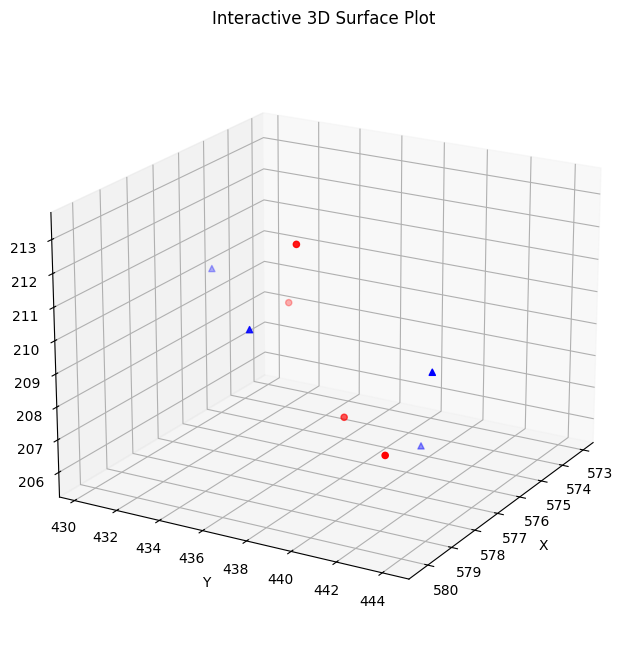

2.896889594059577


In [53]:
import matplotlib
plt.close()
set_1 = coordinates[subgraphs_4[66]]
set_2 = coordinates[subgraphs_4[34]]
res_rmsd, aligned, transform = best_kabsch_alignment(set_1, set_2)
%matplotlib inline
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d', elev=20, azim=30)
ax.scatter(set_1[:, 0], set_1[:, 1], set_1[:, 2], c='r', marker='o', label='Set 1')
ax.scatter(aligned[:, 0], aligned[:, 1], aligned[:, 2], c='b', marker='^', label='Aligned Set 2')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.title('Interactive 3D Surface Plot')
plt.show()
print(res_rmsd)

In [18]:
rmsd_matrix = np.zeros((len(subgraphs_4), len(subgraphs_4))) 
for i in range(len(subgraphs_4)):
    for j in range(i,len(subgraphs_4)):
        if i == j:
            continue
        print(i,j)
        set_1 = coordinates[subgraphs_4[i]]
        set_2 = coordinates[subgraphs_4[j]]
        res_rmsd, aligned, transform = best_kabsch_alignment(set_1, set_2)
        rmsd_matrix[i,j] = res_rmsd
        rmsd_matrix[j,i] = res_rmsd

0 1
0 2
0 3
0 4
0 5
0 6
0 7
0 8
0 9
0 10
0 11
0 12
0 13
0 14
0 15
0 16
0 17
0 18
0 19
0 20
0 21
0 22
0 23
0 24
0 25
0 26
0 27
0 28
0 29
0 30
0 31
0 32
0 33
0 34
0 35
0 36
0 37
0 38
0 39
0 40
0 41
0 42
0 43
0 44
0 45
0 46
0 47
0 48
0 49
0 50
0 51
0 52
0 53
0 54
0 55
0 56
0 57
0 58
0 59
0 60
0 61
0 62
0 63
0 64
0 65
0 66
0 67
0 68
0 69
0 70
0 71
0 72
0 73
0 74
0 75
0 76
0 77
0 78
0 79
0 80
0 81
0 82
0 83
0 84
0 85
0 86
0 87
0 88
0 89
0 90
0 91
0 92
0 93
0 94
0 95
0 96
0 97
0 98
0 99
0 100
0 101
0 102
0 103
0 104
0 105
0 106
0 107
0 108
0 109
0 110
0 111
0 112
0 113
0 114
0 115
0 116
0 117
0 118
0 119
0 120
0 121
0 122
0 123
0 124
0 125
0 126
0 127
0 128
0 129
0 130
0 131
0 132
0 133
0 134
0 135
0 136
0 137
0 138
0 139
0 140
0 141
0 142
0 143
0 144
0 145
0 146
0 147
0 148
0 149
0 150
0 151
0 152
0 153
0 154
0 155
0 156
0 157
0 158
0 159
0 160
0 161
0 162
0 163
0 164
0 165
0 166
0 167
0 168
0 169
0 170
0 171
0 172
0 173
0 174
0 175
0 176
0 177
0 178
0 179
0 180
0 181
0 182
0 183
0 184
0 18

In [22]:
# Find coordinates of smallest RMSD larger than 0.5
rm2 = rmsd_matrix.copy()
rm2[rm2 < 0.5] = np.inf
indices = np.unravel_index(np.argmin(rm2, axis=None), rm2.shape)
print(indices)
print(subgraphs_4[indices[0]])
print(subgraphs_4[indices[1]])

(226, 252)
[48, 111, 115, 90]
[65, 128, 69, 97]


In [ ]:
np.save("subgraph4_rmsd_matrix.npy",rmsd_matrix)

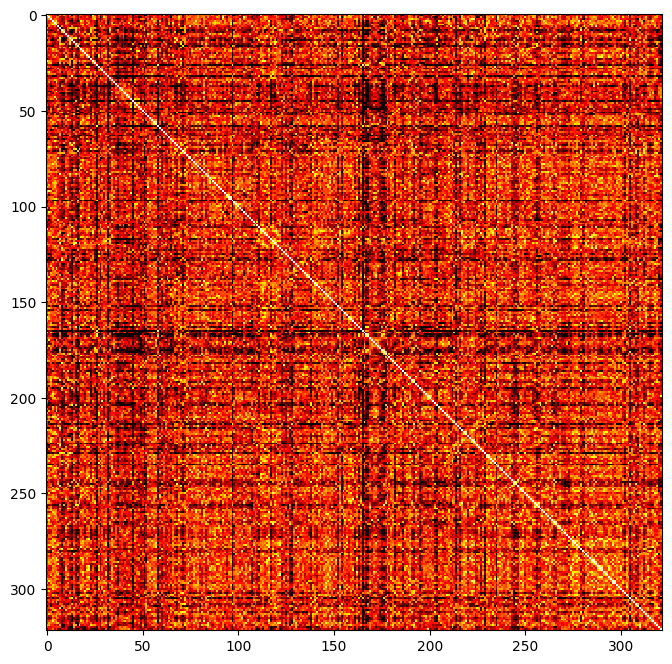

In [100]:
%matplotlib inline
plt.close()
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='rectilinear')
ax.imshow(rmsd_matrix, cmap='hot_r', interpolation='nearest',vmin=0, vmax=6)

plt.show()

In [79]:
(rmsd_matrix < 1).sum()

134

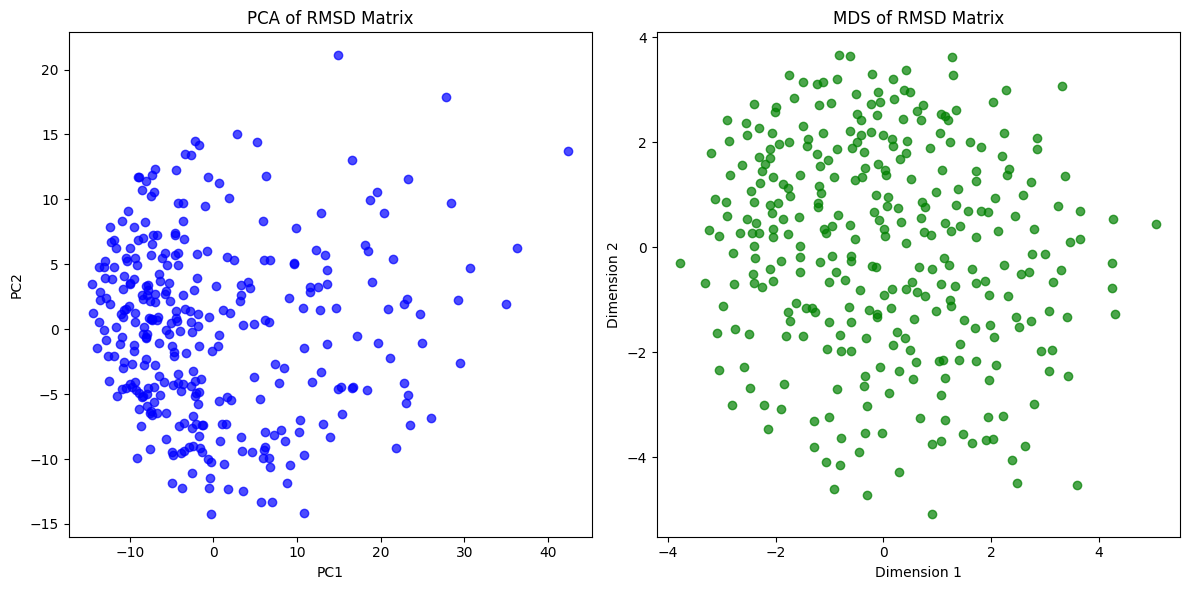

In [101]:
from sklearn.decomposition import PCA
from sklearn.manifold import MDS

import matplotlib.pyplot as plt

# Perform PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(rmsd_matrix)

# Perform MDS
mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42)
mds_result = mds.fit_transform(rmsd_matrix)

# Plot PCA results
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.scatter(pca_result[:, 0], pca_result[:, 1], c='blue', alpha=0.7)
plt.title('PCA of RMSD Matrix')
plt.xlabel('PC1')
plt.ylabel('PC2')

# Plot MDS results
plt.subplot(1, 2, 2)
plt.scatter(mds_result[:, 0], mds_result[:, 1], c='green', alpha=0.7)
plt.title('MDS of RMSD Matrix')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')

plt.tight_layout()
plt.show()

In [ ]:
subgraph_centered_coordinates

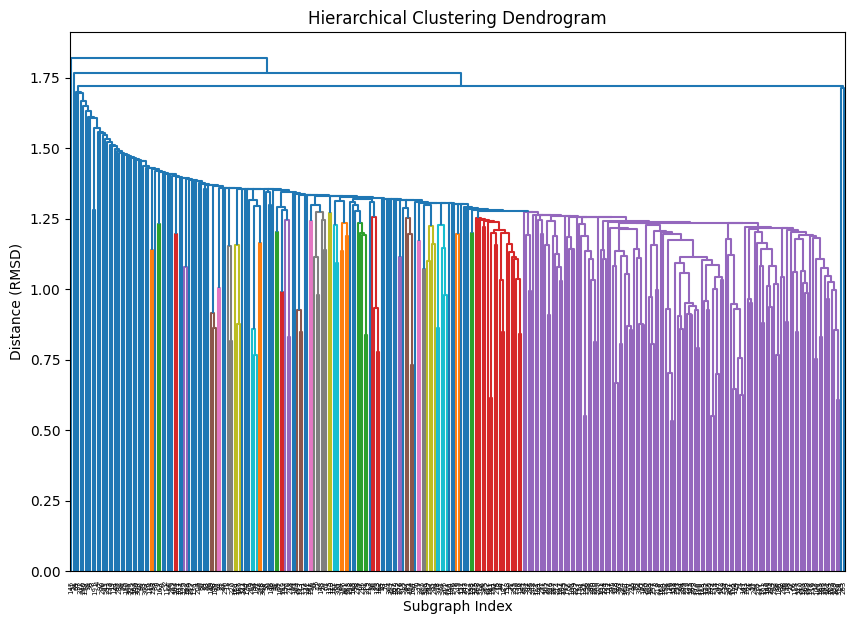

Largest cluster indices: [ 14  28  64 110 118 126 132 155 158 172 175 176 193 196 199 229 244 254
 259 266 267 273 274 292 293 299]
[ 0  1  1  2  1  1  2  2  1  1  3  2  3  3  3  2  1  1  1  1  1  1  2  2
  1  3  1  1  3  2  1  1  1  2  1  2  2  4  1  1  1  1  3  1  1  2  3  1
  1  2  2  2  2  2  3  2  2  1  1  4 10  1  1  1  1  3  2  1  3  5  4  7
  1  3  9  5  1  5 26  1  1  8  3 10  1  2  2 20  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1]


In [87]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Assuming rmsd_matrix is your precomputed RMSD matrix
# Ensure the matrix is condensed for hierarchical clustering
condensed_rmsd = np.tril(rmsd_matrix, -1)[np.tril(rmsd_matrix, -1) > 0]

# Perform hierarchical clustering using the 'average' linkage method
Z = linkage(condensed_rmsd, method='single')

# Plot the dendrogram
plt.figure(figsize=(10, 7))
dendrogram(Z)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Subgraph Index')
plt.ylabel('Distance (RMSD)')
plt.show()

# Determine clusters based on a distance threshold
threshold = 1.2  # Set an appropriate threshold based on your data
clusters = fcluster(Z, t=threshold, criterion='distance')

# Find the largest cluster
largest_cluster = np.bincount(clusters).argmax()
largest_cluster_indices = np.where(clusters == largest_cluster)[0]
print("Largest cluster indices:", largest_cluster_indices)
print(np.bincount(clusters))

4.570577111675653
4.9563523800245255
4.010979118545321
2.5370255299542186
2.9486136929118656
4.056048592470097
4.077156822134774
1.886376990261565
2.6298771211290646
2.597170810237698
3.507205942224647
3.356692132354524
2.697632860863924
5.119656354754996
6.130290931261393
5.23501581747988
4.162379274789539
3.663685866056038
2.7330259931957657
4.305460113307605
4.370201993557334
3.5702842358414015
4.095382088617326
3.3553517220260565
3.460051996561419


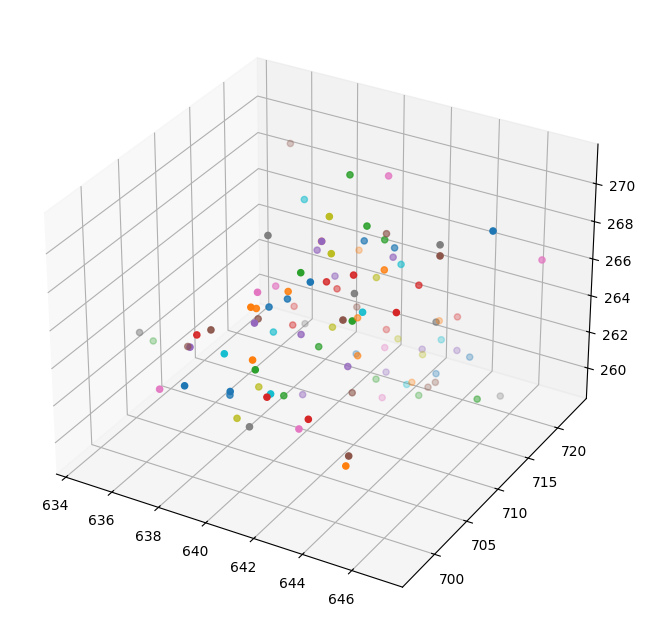

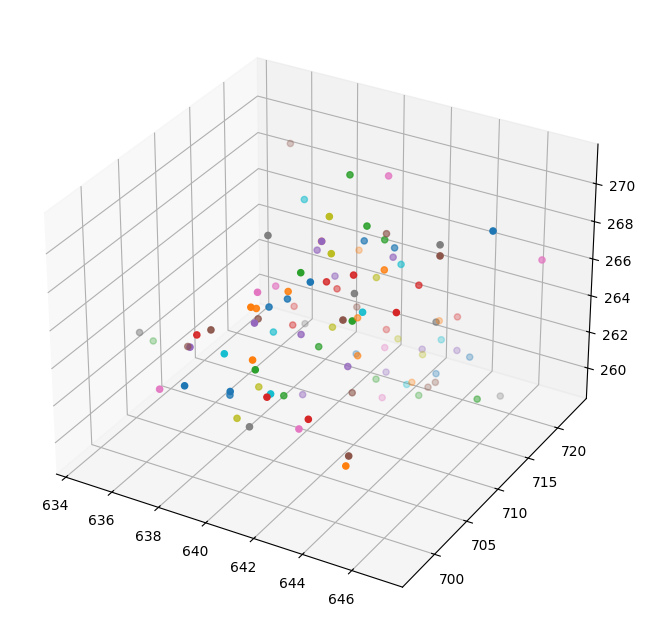

In [89]:
first_cluster = largest_cluster_indices[0]
clusters = [
    coordinates[subgraphs_4[first_cluster]]
]

for i in range(len(largest_cluster_indices)):
    if i ==0:
        continue
    set_1 = coordinates[subgraphs_4[first_cluster]]
    set_2 = coordinates[subgraphs_4[largest_cluster_indices[i]]]
    res_rmsd, aligned, transform = best_kabsch_alignment(set_1, set_2)
    clusters.append(aligned)
    print(res_rmsd)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
for c in clusters:
    ax.scatter(c[:, 0], c[:, 1], c[:, 2],  marker='o', label='Set 1')
fig

In [48]:
subgraphs_6[379]

[382, 221, 234, 241, 186, 208]

In [49]:
subgraphs_6[630]

[241, 350, 338, 448, 221, 439]

In [50]:
subgraphs_6[638]

[755, 350, 387, 448, 607, 221]

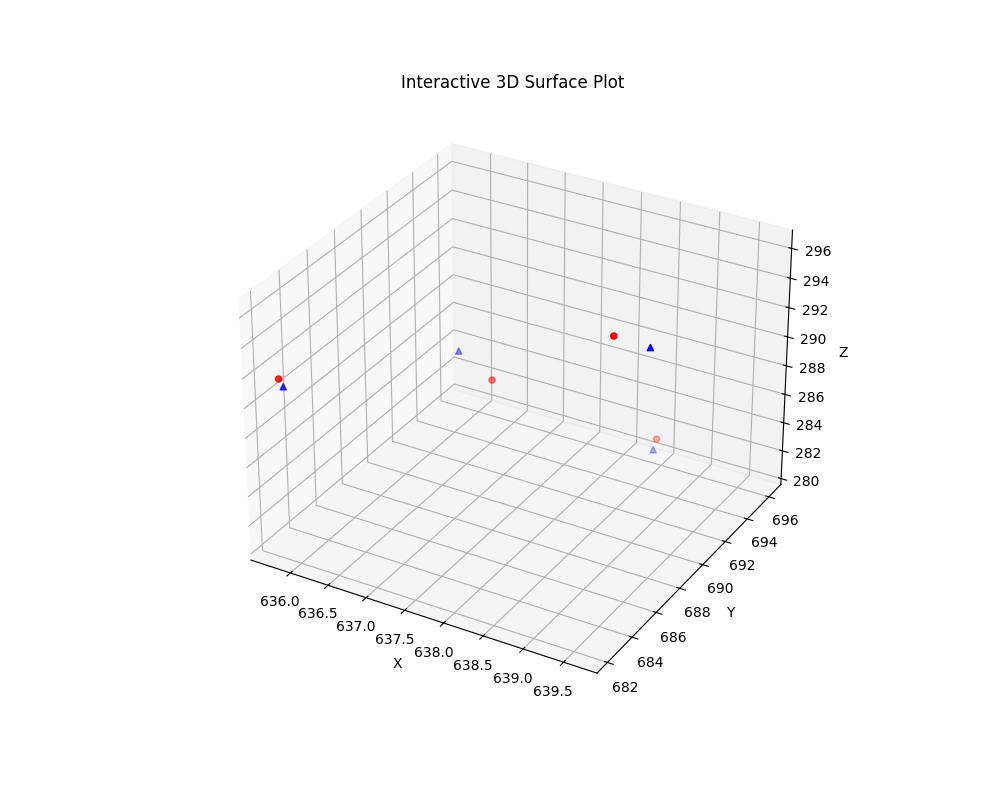

[[-0.96519844  0.2383924  -0.10752222]
 [ 0.20052386  0.41071198 -0.88944131]
 [-0.16787539 -0.88004814 -0.44422193]]


In [21]:
import matplotlib
set_1 = coordinates[subgraphs_4[good_ones[0][0]]]
set_2 = coordinates[subgraphs_4[good_ones[0][1]]]
res_rmsd, aligned, transform = best_kabsch_alignment(set_1, set_2)
%matplotlib widget
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(set_1[:, 0], set_1[:, 1], set_1[:, 2], c='r', marker='o', label='Set 1')
ax.scatter(aligned[:, 0], aligned[:, 1], aligned[:, 2], c='b', marker='^', label='Aligned Set 2')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.title('Interactive 3D Surface Plot')
plt.show()


In [26]:
for idx, (i, j) in enumerate(good_ones):
    subgraph_i = set(subgraphs_4[i])
    subgraph_j = set(subgraphs_4[j])
    common_aunps = subgraph_i.intersection(subgraph_j)
    
    print(f"Pair {idx}: Subgraphs {i} and {j} : {len(common_aunps)}")
  
    

Pair 0: Subgraphs 3 and 102 : 0
Pair 1: Subgraphs 6 and 7 : 3
Pair 2: Subgraphs 8 and 12 : 3
Pair 3: Subgraphs 10 and 13 : 3
Pair 4: Subgraphs 16 and 120 : 0
Pair 5: Subgraphs 18 and 206 : 0
Pair 6: Subgraphs 18 and 272 : 0
Pair 7: Subgraphs 22 and 286 : 0
Pair 8: Subgraphs 23 and 216 : 0
Pair 9: Subgraphs 29 and 208 : 3
Pair 10: Subgraphs 39 and 172 : 0
Pair 11: Subgraphs 49 and 70 : 0
Pair 12: Subgraphs 65 and 103 : 0
Pair 13: Subgraphs 65 and 237 : 0
Pair 14: Subgraphs 78 and 79 : 3
Pair 15: Subgraphs 79 and 273 : 0
Pair 16: Subgraphs 83 and 243 : 0
Pair 17: Subgraphs 86 and 126 : 0
Pair 18: Subgraphs 88 and 93 : 3
Pair 19: Subgraphs 91 and 206 : 0
Pair 20: Subgraphs 91 and 256 : 0
Pair 21: Subgraphs 93 and 286 : 0
Pair 22: Subgraphs 95 and 161 : 0
Pair 23: Subgraphs 108 and 146 : 3
Pair 24: Subgraphs 109 and 111 : 3
Pair 25: Subgraphs 114 and 123 : 3
Pair 26: Subgraphs 116 and 217 : 0
Pair 27: Subgraphs 119 and 222 : 3
Pair 28: Subgraphs 121 and 240 : 0
Pair 29: Subgraphs 121 and 2

NameError: name 'load_tomogram' is not defined

In [ ]:
centers = (selected_aunp_pos_transformed[pairs[:,0]] + selected_aunp_pos_transformed[pairs[:,1]])/2
potential_centers = kdt.query(centers, k=1, distance_upper_bound=4)

pairs = pairs[potential_centers[0] < 4]
potential_centers = potential_centers[1][potential_centers[0] < 4]
pt_dis = 8
potential_points = kdt.query_ball_point(selected_aunp_pos_transformed[potential_centers], pt_dis)

potential_ps = []
for i, potential_point_list in enumerate(potential_points):
    for potential_point in potential_point_list:
        if potential_point in pairs[i] or potential_point == potential_centers[i]:
            continue
        if np.linalg.norm(selected_aunp_pos_transformed[pairs[i][0]] - selected_aunp_pos_transformed[potential_point]) < pt_dis:
            potential_ps.append([pairs[i][1], potential_centers[i], pairs[i][0], potential_point])
            continue
        if np.linalg.norm(selected_aunp_pos_transformed[pairs[i][1]] - selected_aunp_pos_transformed[potential_point]) < pt_dis:
            potential_ps.append([pairs[i][0], potential_centers[i], pairs[i][1], potential_point])
            continue


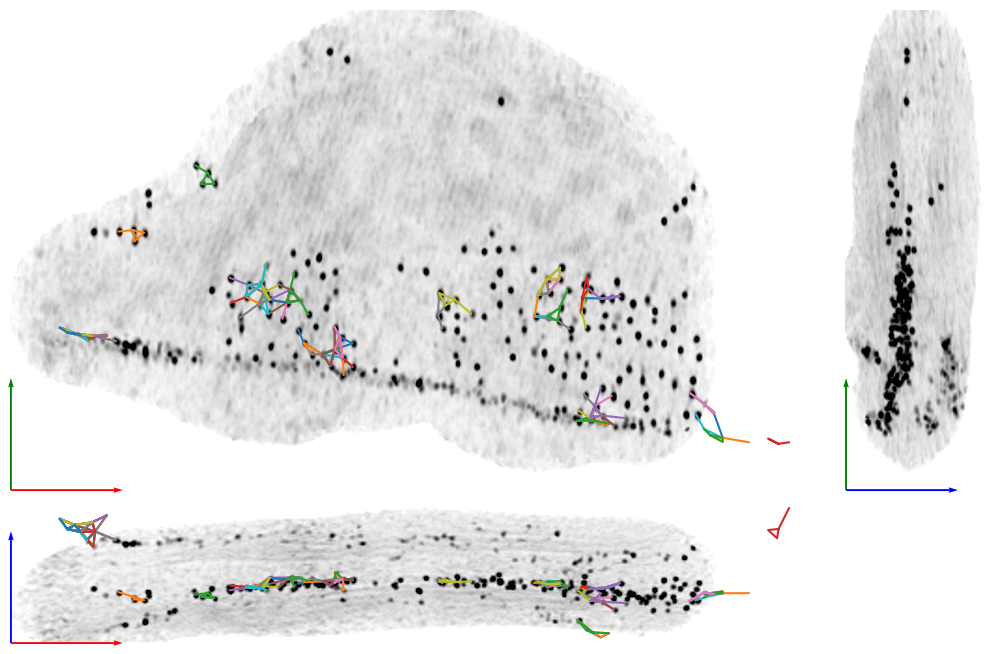

In [ ]:

(axxy, axyz, axxz) = fig.get_axes()
for (i, j, k, l) in potential_ps:

    axxy.plot([selected_aunp_pos_transformed[i, 0], selected_aunp_pos_transformed[j, 0], selected_aunp_pos_transformed[k, 0], selected_aunp_pos_transformed[l, 0], selected_aunp_pos_transformed[j, 0]], 
            [selected_aunp_pos_transformed[i, 1], selected_aunp_pos_transformed[j, 1], selected_aunp_pos_transformed[k,1],selected_aunp_pos_transformed[l,1], selected_aunp_pos_transformed[j,1]], "-")
    axxz.plot([selected_aunp_pos_transformed[i, 0], selected_aunp_pos_transformed[j, 0], selected_aunp_pos_transformed[k, 0], selected_aunp_pos_transformed[l, 0], selected_aunp_pos_transformed[j, 0]],
            [selected_aunp_pos_transformed[i, 2], selected_aunp_pos_transformed[j, 2], selected_aunp_pos_transformed[k,2],selected_aunp_pos_transformed[l,2], selected_aunp_pos_transformed[j,2]], "-")
fig

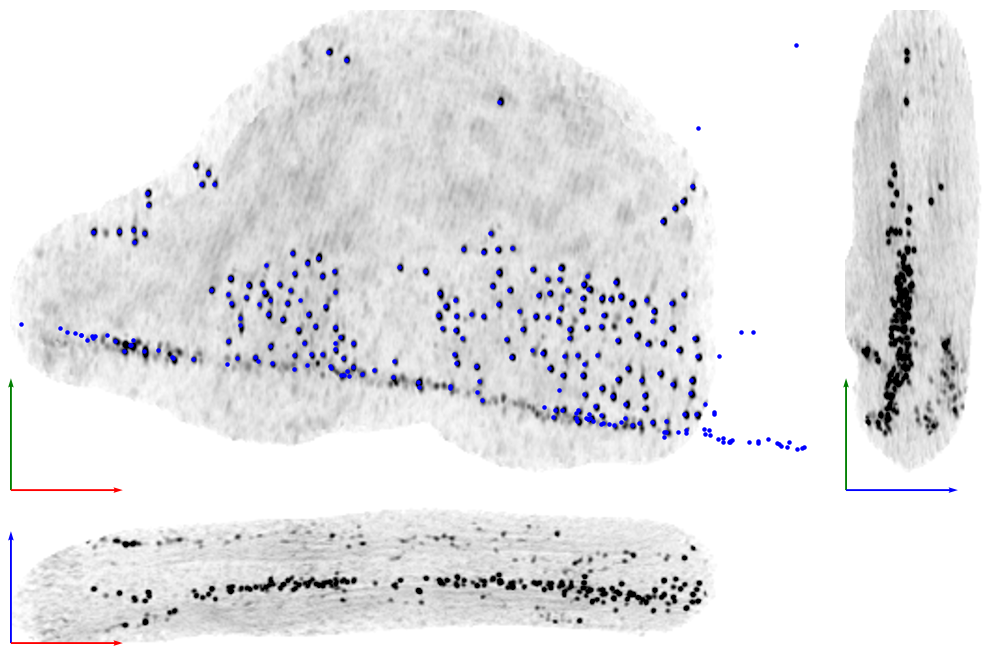

In [ ]:
az = basefolder / tomos[0][0] / "best_alignment" / "active_zonograms" / f"active_zonogram_{tomos[0][1]}.mrc"
res_ddw, rshape = load_tomogram(az)
fig = render_active_zonograms((None,None,res_ddw))
az_data = np.load(az.with_suffix(".npy") ,allow_pickle=True)
sel_aunps = starfile.read(basefolder / tomos[0][0] / "best_alignment" / "aunps" / f"aunp_tm_BP_active_zone_{tomos[0][1]}.star")
selected_aunp_pos = sel_aunps[["faCoordinateX", "faCoordinateY", "faCoordinateZ"]].values 
selected_aunp_pos_transformed = (selected_aunp_pos - az_data.tolist()["center"]) @ az_data.tolist()["cs"].T
selected_aunp_pos_transformed += np.floor(np.array(rshape)[[2,1,0]]/2)
selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed > 0, axis=1)]
selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed < np.array(rshape)[[2,1,0]], axis=1)]

(axxy, axxz, axyz) = fig.get_axes()

axxy.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,1], c="b", s=5)

fig